# Backtests: Kupiec, Christoffersen, the duration test, dynamic quantile and the Basel traffic light

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (VaR, ES and a first exceedance count)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state the null hypothesis, the statistic and the distribution of the Kupiec, Christoffersen, duration and dynamic quantile tests, and reproduce the first two from their closed forms;
- explain why the exact binomial p-value matters when the expected number of exceedances is small, and show it on a 250-day window at the 1 percent level;
- read the Basel traffic light as a cumulative binomial probability, and compute its zones and multipliers;
- rerun the whole exceedance battery on the exceedance flags of a committed window and obtain the committed rows, including the Monte Carlo p-values;
- say which of the tests detect a wrong count and which detect clustered exceedances, from the committed results of the crisis windows.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 as Contraste commits it: four windows of the market-risk back-test, each holding the VaR path, the exceedance days and the committed test rows of 17 models at the tail levels 1 and 2.5 percent.

- `calm-2004-06`: three calm years, 750 forecast days (the control window).
- `equity-2007-09`: the financial crisis, 504 days.
- `equity-2020`: the pandemic crash, 104 days.
- `rates-2022`: the hiking cycle, a 10-year Treasury position, 249 days.

All four store the days on which the loss exceeded the VaR, which is all the exceedance tests read. The tests use **flags** (1 on an exceedance day), so the notebook rebuilds the flags from the stored days and the VaR path from the committed file. The committed `tests` rows were baked with an older engine than the one installed; the notebook prints both versions and compares every recomputation with the committed row. The next cell loads the windows and defines the one helper the notebook uses.

In [2]:
# Load the four windows and define the helper that rebuilds the exceedance flags and the committed test row of one model and level
ROOT = Path("../../..").resolve()
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022")
windows = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}


def series_of(window, model_id, alpha):
    """The exceedance flags, the VaR path (loss numbers) and the committed rows of one model at one tail level."""
    doc = windows[window]
    model = {m["model_id"]: m for m in doc["outputs"]["models"]}[model_id]
    level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
    flags = np.zeros(level["n_scored"], dtype=bool)
    flags[level["exceedance_days"]] = True
    rows = {t["test_id"]: t for t in doc["tests"] if t["model_id"] == model_id and t["segment"] == f"alpha={alpha:g}"}
    return flags, np.array(level["var"]), rows


print("committed rows baked by riskvalidation", windows["equity-2007-09"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for w in WINDOWS:
    flags, var, rows = series_of(w, "hs-250", 0.01)
    print(f"{w:15s} days {flags.size:4d} | hs-250 exceedances at 1%: {int(flags.sum()):3d} | expected {0.01 * flags.size:5.2f} | committed tests per model and level: {len(rows)}")

committed rows baked by riskvalidation 0.7.0 | installed 0.9.0
calm-2004-06    days  750 | hs-250 exceedances at 1%:   9 | expected  7.50 | committed tests per model and level: 6
equity-2007-09  days  504 | hs-250 exceedances at 1%:  19 | expected  5.04 | committed tests per model and level: 6
equity-2020     days  104 | hs-250 exceedances at 1%:   8 | expected  1.04 | committed tests per model and level: 6
rates-2022      days  249 | hs-250 exceedances at 1%:   8 | expected  2.49 | committed tests per model and level: 6


## Method

### Step 1: Kupiec's proportion of failures

If the VaR is right the exceedance indicator $I_t$ is a sequence of independent Bernoulli($\alpha$) variables, so $x = \sum_t I_t$ in $T$ days is binomial($T$, $\alpha$). Kupiec (1995) tests $H_0: \Pr(I_t = 1) = \alpha$ with the likelihood ratio of the observed share $\hat\pi = x/T$ against $\alpha$, using the convention $0\ln 0 = 0$:

$$LR_{POF} = -2\ln\frac{(1-\alpha)^{T-x}\,\alpha^{x}}{(1-\hat\pi)^{T-x}\,\hat\pi^{x}} \;\xrightarrow{d}\; \chi^2_1$$

The engine's `kupiec_pof` returns the statistic, the asymptotic p-value and, in `metric`, the exact binomial p-value: the total probability, under binomial($T$, $\alpha$), of the counts that are at most as likely as the observed $x$. The cell computes both by hand from the definitions, for `hs-250` in the crisis, and compares them with the engine and with the committed row.

In [3]:
# Kupiec by hand from the definition (statistic, asymptotic p, exact p), against the engine and the committed row
from riskvalidation.validation.market import kupiec_pof

alpha = 0.01
flags, var, rows = series_of("equity-2007-09", "hs-250", alpha)
T, x = flags.size, int(flags.sum())
pi_hat = x / T
lr = -2.0 * ((T - x) * math.log(1 - alpha) + special.xlogy(x, alpha) - (T - x) * math.log(1 - pi_hat) - special.xlogy(x, pi_hat))
p_asymptotic = stats.chi2.sf(lr, 1)
pmf = stats.binom.pmf(np.arange(T + 1), T, alpha)
p_exact = pmf[pmf <= pmf[x] * (1 + 1e-7)].sum()
print(f"T {T}, x {x}, expected {alpha * T:.2f}, observed share {pi_hat:.4f}")
print(f"by hand : LR {lr:.4f} | asymptotic p {p_asymptotic:.3e} | exact p {p_exact:.3e}")

engine = kupiec_pof(flags, alpha, model_id="hs-250")
row = rows["market.kupiec_pof"]
print(f"engine  : LR {engine.statistic:.4f} | asymptotic p {engine.p_value:.3e} | exact p {engine.metric:.3e} | light {LIGHT[engine.light.value]}")
print(f"committed: LR {row['statistic']:.4f} | asymptotic p {row['p_value']:.3e} | exact p {row['metric']:.3e} | light {LIGHT[row['light']]}")

T 504, x 19, expected 5.04, observed share 0.0377
by hand : LR 22.9015 | asymptotic p 1.705e-06 | exact p 1.303e-06
engine  : LR 22.9015 | asymptotic p 1.705e-06 | exact p 1.303e-06 | light red
committed: LR 22.9015 | asymptotic p 1.705e-06 | exact p 1.303e-06 | light red


### Step 2: when the expected count is small

On a 250-day window at the 1 percent level the expected count is 2.5. The chi-square law is then a poor approximation of a discrete statistic that can only take a few values, and the asymptotic and the exact p-values can sit on opposite sides of a threshold. The next cell builds a 250-day flag series with $x$ exceedances for $x = 0,\dots,10$ and prints both p-values, with the light the Contraste gate (amber below 0.10, red below 0.05) gives each. The gate is an internal convention, not a regulatory threshold.

In [4]:
# Asymptotic against exact p-value for every count from 0 to 10 in a 250-day window at the 1% level
print(f"{'x':>3s} {'asymptotic p':>13s} {'exact p':>9s}  light by the asymptotic p")
for count in range(0, 11):
    series = np.zeros(250, dtype=bool)
    series[:count] = True                               # the position of the flags does not matter to this test
    result = kupiec_pof(series, 0.01)
    print(f"{count:3d} {result.p_value:13.4f} {result.metric:9.4f}  {LIGHT[result.light.value]}")

  x  asymptotic p   exact p  light by the asymptotic p
  0        0.0250    0.1889  red
  1        0.2781    0.5276  green
  2        0.7419    1.0000  green
  3        0.7580    0.7426  green
  4        0.3805    0.3229  green
  5        0.1619    0.1078  green
  6        0.0594    0.0412  amber
  7        0.0190    0.0137  red
  8        0.0054    0.0040  red
  9        0.0014    0.0011  red
 10        0.0003    0.0003  red


### Step 3: Christoffersen's independence and conditional coverage

A model can have the right number of exceedances and still be wrong if they come in bunches. Christoffersen (1998) tests the exceedance sequence against a first-order Markov chain. Let $n_{ij}$ be the number of days on which state $i$ was followed by state $j$ ($0$ no exceedance, $1$ exceedance), $\pi_{01} = n_{01}/(n_{00}+n_{01})$, $\pi_{11} = n_{11}/(n_{10}+n_{11})$ and $\pi = (n_{01}+n_{11})/(n_{00}+n_{01}+n_{10}+n_{11})$:

$$LR_{ind} = -2\ln\frac{(1-\pi)^{n_{00}+n_{10}}\,\pi^{n_{01}+n_{11}}}{(1-\pi_{01})^{n_{00}}\,\pi_{01}^{n_{01}}\,(1-\pi_{11})^{n_{10}}\,\pi_{11}^{n_{11}}} \xrightarrow{d} \chi^2_1, \qquad LR_{cc} = LR_{POF} + LR_{ind} \xrightarrow{d} \chi^2_2$$

Independence holds when $\pi_{01} = \pi_{11}$: an exceedance does not change tomorrow's chance of another. The cell counts the transitions of the `garch-t` flags in the crisis at 2.5 percent, computes the statistics by hand, and compares them with `christoffersen_independence` and `christoffersen_conditional_coverage`.

In [5]:
# Transition counts and the Christoffersen statistics by hand, against the engine and the committed rows
from riskvalidation.validation.market import christoffersen_conditional_coverage, christoffersen_independence

alpha = 0.025
flags, var, rows = series_of("equity-2007-09", "garch-t", alpha)
before, after = flags[:-1], flags[1:]
n00, n01 = int(np.sum(~before & ~after)), int(np.sum(~before & after))
n10, n11 = int(np.sum(before & ~after)), int(np.sum(before & after))
pi01, pi11 = n01 / (n00 + n01), n11 / (n10 + n11)
pi = (n01 + n11) / (n00 + n01 + n10 + n11)
print(f"transitions: n00 {n00}, n01 {n01}, n10 {n10}, n11 {n11}")
print(f"P(exceedance | none yesterday) {pi01:.4f} | P(exceedance | exceedance yesterday) {pi11:.4f} | unconditional {pi:.4f}")

null = special.xlogy(n00 + n10, 1 - pi) + special.xlogy(n01 + n11, pi)
alternative = (special.xlogy(n00, 1 - pi01) + special.xlogy(n01, pi01) + special.xlogy(n10, 1 - pi11) + special.xlogy(n11, pi11))
lr_ind = -2.0 * (null - alternative)
print(f"by hand: LR_ind {lr_ind:.4f} | p {stats.chi2.sf(lr_ind, 1):.4f}")

ind = christoffersen_independence(flags, alpha, model_id="garch-t")
cc = christoffersen_conditional_coverage(flags, alpha, model_id="garch-t")
for label, result, key in (("independence", ind, "market.christoffersen_independence"), ("conditional coverage", cc, "market.christoffersen_conditional_coverage")):
    print(f"{label:21s}: engine LR {result.statistic:.4f} p {result.p_value:.4f} {LIGHT[result.light.value]} | "
          f"committed LR {rows[key]['statistic']:.4f} p {rows[key]['p_value']:.4f} {LIGHT[rows[key]['light']]}")
print(f"LR_cc = LR_POF + LR_ind: {cc.extras['lr_pof']:.4f} + {cc.extras['lr_ind']:.4f} = {cc.statistic:.4f}")

transitions: n00 441, n01 31, n10 31, n11 0
P(exceedance | none yesterday) 0.0657 | P(exceedance | exceedance yesterday) 0.0000 | unconditional 0.0616
by hand: LR_ind 4.0750 | p 0.0435
independence         : engine LR 4.0750 p 0.0435 red | committed LR 4.0750 p 0.0435 red
conditional coverage : engine LR 23.7907 p 0.0000 red | committed LR 23.7907 p 0.0000 red
LR_cc = LR_POF + LR_ind: 19.7157 + 4.0750 = 23.7907


### Step 4: the duration test

The independence test looks only one day ahead. Christoffersen and Pelletier (2004) look at the **durations** $D_i$, the days between consecutive exceedances. If coverage is right and the exceedances are independent, the durations are memoryless (geometric, close to exponential), and the probability of an exceedance does not depend on the time since the last one. They model the hazard as Weibull, $\lambda(d) = a^b\,b\,d^{\,b-1}$, with $b = 1$ under the null, so $b < 1$ is a decreasing hazard (bunching) and $b > 1$ an increasing one (too regular). The statistic is the likelihood ratio of $b = 1$, with the first and last spells censored, and its p-value is by Monte Carlo (draws of Bernoulli($\alpha$) sequences of the same length). The Weibull form is the standard one in the literature; the engine documents that it was not re-checked against the paper's full text.

The cell lists the completed durations of `hs-250` in the crisis at 1 percent, runs `duration_test` with the committed number of draws and seed, and compares with the committed row. The same inputs and the same seed give the same p-value.

In [6]:
# Durations between exceedances, then the duration test with the committed draws and seed against the committed row
from riskvalidation.validation.market import duration_test

alpha = 0.01
flags, var, rows = series_of("equity-2007-09", "hs-250", alpha)
days = np.flatnonzero(flags)
durations = np.diff(days)
print(f"exceedances {days.size} | completed durations {durations.size} | mean {durations.mean():.1f} days | expected under the null {1 / alpha:.0f}")
print("durations:", durations.tolist())

row = rows["market.duration_test"]
engine = duration_test(flags, alpha, model_id="hs-250", n_mc=10000, seed=42)
print(f"engine   : LR {engine.statistic:.4f} | Weibull b {engine.extras['weibull_b']:.3f} | p {engine.p_value:.4f} | light {LIGHT[engine.light.value]}")
print(f"committed: LR {row['statistic']:.4f} | Weibull b {row['extras']['weibull_b']:.3f} | p {row['p_value']:.4f} | light {LIGHT[row['light']]}")

exceedances 19 | completed durations 18 | mean 19.1 days | expected under the null 100
durations: [2, 6, 4, 63, 48, 12, 85, 14, 48, 3, 4, 2, 3, 5, 6, 2, 4, 32]
engine   : LR 5.1768 | Weibull b 0.690 | p 0.0824 | light amber
committed: LR 5.1768 | Weibull b 0.690 | p 0.0824 | light amber


### Step 5: the dynamic quantile test

Engle and Manganelli (2004) ask whether the exceedances are **predictable** from anything known the day before. Regress the demeaned hit $\mathrm{Hit}_t = I_t - \alpha$ on a constant, four lagged hits and the current VaR, collected in the matrix $X$. Under correct conditional coverage no coefficient differs from zero, and the quadratic form

$$DQ = \frac{\mathrm{Hit}^{\top} X\,(X^{\top}X)^{+}\,X^{\top}\mathrm{Hit}}{\alpha(1-\alpha)}$$

is asymptotically chi-square with the rank of $X$ degrees of freedom. With sparse hits that law is poor: the engine records that the plain test rejected correct forecasts far more often than 5 percent, so its light follows a **Monte Carlo p-value** and the asymptotic one stays in `extras`. The cell computes the quadratic form by hand from the definition on the `hs-250` flags and compares it with the engine's statistic and p-values.

In [7]:
# The DQ quadratic form by hand (4 lags), against the engine's statistic, its two p-values and the committed row
from riskvalidation.validation.market import dynamic_quantile_test

lags = 4
hits = flags.astype(float)
X = np.column_stack([np.ones(hits.size - lags)] + [hits[lags - j:hits.size - j] for j in range(1, lags + 1)] + [var[lags:]])
hit_demeaned = hits[lags:] - alpha
dq_by_hand = float(hit_demeaned @ X @ np.linalg.pinv(X.T @ X) @ X.T @ hit_demeaned) / (alpha * (1 - alpha))
print(f"regression: {X.shape[0]} days, {X.shape[1]} columns (constant, {lags} lags, VaR), rank {np.linalg.matrix_rank(X)}")
print(f"by hand: DQ {dq_by_hand:.4f}")

row = rows["market.dynamic_quantile_test"]
engine = dynamic_quantile_test(flags, var, alpha, lags=lags, model_id="hs-250", n_mc=10000, seed=42)
print(f"engine   : DQ {engine.statistic:.4f} | Monte Carlo p {engine.p_value:.4f} | asymptotic p {engine.extras['p_value_asymptotic']:.4f} | light {LIGHT[engine.light.value]}")
print(f"committed: DQ {row['statistic']:.4f} | Monte Carlo p {row['p_value']:.4f} | asymptotic p {row['extras']['p_value_asymptotic']:.4f} | light {LIGHT[row['light']]}")

regression: 500 days, 6 columns (constant, 4 lags, VaR), rank 6
by hand: DQ 121.1612
engine   : DQ 121.1612 | Monte Carlo p 0.0003 | asymptotic p 0.0000 | light red
committed: DQ 121.1612 | Monte Carlo p 0.0003 | asymptotic p 0.0000 | light red


### Step 6: the Basel traffic light

The 1996 Basel framework judges a bank's 99 percent VaR by the number of exceptions $k$ in the last 250 trading days. Under a correct model $k \sim$ binomial(250, 0.01), and the zones are cut on the cumulative probability $P(X \le k)$: **green** below the count where it first reaches 95 percent, **amber** from there, **red** from the count where it reaches 99.99 percent. The multiplier $m_c$ of the capital charge rises with the zone (MAR32.9 Table 1). The engine has the three pieces as functions: `binomial_cumulative_probability`, `traffic_light_zone` and `mar32_multiplier`; the cell prints them for 0 to 12 exceptions. The multiplier printed is the backtesting-dependent multiplier $m_c$ of MAR32.9, 1.50 to 2.00; the committed ladder document lists beside it the older US factor of 3.00 to 4.00.

In [8]:
# The traffic-light table: cumulative probability, zone and multiplier for 0 to 12 exceptions in 250 days at 99% coverage
from riskvalidation.market.frtb import binomial_cumulative_probability, mar32_multiplier, traffic_light_zone

print(f"{'exceptions':>10s} {'P(X <= k)':>10s}  {'zone':6s} {'multiplier':>10s}")
for k in range(0, 13):
    probability = binomial_cumulative_probability(k, 250, 0.01)
    print(f"{k:10d} {100 * probability:9.4f}%  {LIGHT[traffic_light_zone(k)]:6s} {mar32_multiplier(k):10.2f}")

exceptions  P(X <= k)  zone   multiplier
         0    8.1059%  green        1.50
         1   28.5752%  green        1.50
         2   54.3169%  green        1.50
         3   75.8117%  green        1.50
         4   89.2188%  green        1.50
         5   95.8817%  amber        1.70
         6   98.6299%  amber        1.76
         7   99.5975%  amber        1.83
         8   99.8943%  amber        1.88
         9   99.9750%  amber        1.92
        10   99.9946%  red          2.00
        11   99.9989%  red          2.00
        12   99.9998%  red          2.00


The light is a function of the last 250 days, so over a longer window it can be computed on every rolling window. The committed artifact stores, for each model, how many of the rolling windows were green, amber and red. The next cell recomputes the zone of the rolling 250-day count for `hs-250` and `ewma` in the crisis, and compares the tally and the final zone with the committed `traffic_light` block and with the engine's `basel_traffic_light` on the last 250 days.

In [9]:
# Rolling 250-day exception counts and their zones, against the committed tally and the engine's light on the last 250 days
from riskvalidation.validation.market import basel_traffic_light

rolling = {}
for model_id in ("hs-250", "ewma"):
    flags, var, rows = series_of("equity-2007-09", model_id, 0.01)
    running = np.concatenate([[0], np.cumsum(flags)])
    counts = (running[250:] - running[:-250]).astype(int)           # exceptions in each window of 250 days
    zones = [traffic_light_zone(int(k)) for k in counts]
    tally = {z: zones.count(z) for z in ("green", "amber", "red")}
    committed = [m for m in windows["equity-2007-09"]["outputs"]["models"] if m["model_id"] == model_id][0]["by_level"][0]["traffic_light"]
    light = basel_traffic_light(flags, model_id=model_id)
    rolling[model_id] = counts
    print(f"{model_id}: {counts.size} windows | maximum {counts.max()} exceptions | tally {tally}")
    print(f"  committed: green {committed['days_green']}, amber {committed['days_amber']}, red {committed['days_red']}, maximum {committed['max_rolling_exceedances']}")
    print(f"  last window: {int(light.statistic)} exceptions, cumulative probability {light.metric:.4f}%, zone {LIGHT[light.light.value]}, multiplier {light.extras['mar32_multiplier']}")

hs-250: 255 windows | maximum 14 exceptions | tally {'green': 0, 'amber': 60, 'red': 195}
  committed: green 0, amber 60, red 195, maximum 14
  last window: 10 exceptions, cumulative probability 99.9946%, zone red, multiplier 2.0
ewma: 255 windows | maximum 12 exceptions | tally {'green': 0, 'amber': 229, 'red': 26}
  committed: green 0, amber 229, red 26, maximum 12
  last window: 7 exceptions, cumulative probability 99.5975%, zone amber, multiplier 1.83


### Step 7: the whole battery against the committed rows

The engine's functions are deterministic for a fixed seed, so the committed `tests` rows must come back exactly from the flags and the VaR path. The cell reruns Kupiec, independence, conditional coverage, duration (10,000 draws, seed 42) and dynamic quantile (lags 4, 10,000 draws, seed 42) for `hs-250`, at both levels, in the three crisis windows, and reports the largest difference between a recomputed and a committed statistic or p-value. A test the engine cannot evaluate (fewer than two exceedances for the duration test) is committed as `not_evaluated`, and the comparison checks that it still is.

In [10]:
# Rerun the five exceedance tests on every window, model and level of the sample and compare each with its committed row
compared, worst, not_evaluated, mismatches = 0, 0.0, 0, 0
for window in ("equity-2007-09", "equity-2020", "rates-2022"):
    for model_id in ("hs-250",):
        for alpha in (0.01, 0.025):
            flags, var, rows = series_of(window, model_id, alpha)
            fresh = {
                "market.kupiec_pof": kupiec_pof(flags, alpha, model_id),
                "market.christoffersen_independence": christoffersen_independence(flags, alpha, model_id),
                "market.christoffersen_conditional_coverage": christoffersen_conditional_coverage(flags, alpha, model_id),
                "market.duration_test": duration_test(flags, alpha, model_id, n_mc=10000, seed=42),
                "market.dynamic_quantile_test": dynamic_quantile_test(flags, var, alpha, lags=4, model_id=model_id, n_mc=10000, seed=42),
            }
            for test_id, result in fresh.items():
                row = rows[test_id]
                if row["light"] == "not_evaluated" or result.light.value == "not_evaluated":
                    not_evaluated += 1
                    mismatches += row["light"] != result.light.value
                    continue
                compared += 1
                worst = max(worst, abs(result.p_value - row["p_value"]), abs(result.statistic - row["statistic"]))
                mismatches += row["light"] != result.light.value
print(f"rows compared {compared} | not evaluated on both sides {not_evaluated} | largest difference {worst:.2e} | lights that differ {mismatches}")

rows compared 30 | not evaluated on both sides 0 | largest difference 5.00e-07 | lights that differ 0


### Step 8: which test sees what

A wrong count and clustered exceedances are different failures, and the battery separates them. The cell reads the committed rows of all 17 models in the three crisis windows and counts, at each level, how many models are red on the coverage test (Kupiec), on independence, and on the duration test. Then it draws the exceedances of `hs-250` and `ewma` in 2007 to 2009 on a time axis, with the rolling 250-day count against the zone boundaries: the red region begins at 10 exceptions.

window           level   coverage (Kupiec)        independence            duration   models
equity-2007-09   0.010                  17                   0                   2   17
equity-2007-09   0.025                  17                   4                   4   17
equity-2020      0.010                  12                   0                   2   17
equity-2020      0.025                  11                   0                   0   17
rates-2022       0.010                   7                   0                   1   17
rates-2022       0.025                  12                   0                   3   17


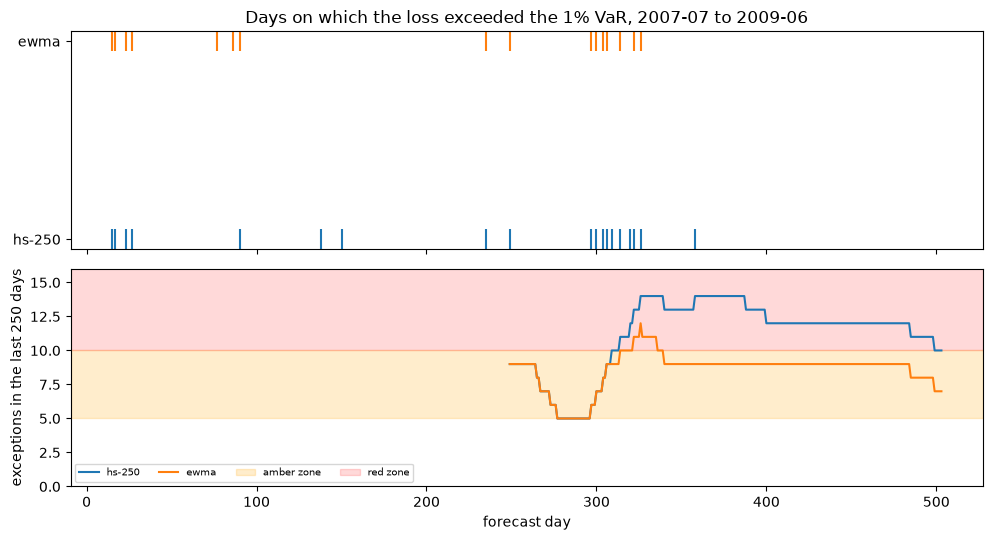

In [11]:
# Count the models that are red on coverage, independence and duration in each crisis window and level, then draw the 2007-09 exceedances
labels = {"market.kupiec_pof": "coverage (Kupiec)", "market.christoffersen_independence": "independence", "market.duration_test": "duration"}
print(f"{'window':15s} {'level':>6s}  " + "  ".join(f"{name:>18s}" for name in labels.values()) + "   models")
for window in ("equity-2007-09", "equity-2020", "rates-2022"):
    for alpha in (0.01, 0.025):
        rows = [t for t in windows[window]["tests"] if t["segment"] == f"alpha={alpha:g}"]
        reds = [sum(t["light"] == "red" for t in rows if t["test_id"] == test_id) for test_id in labels]
        print(f"{window:15s} {alpha:6.3f}  " + "  ".join(f"{r:18d}" for r in reds) + f"   {len({t['model_id'] for t in rows})}")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for position, model_id in enumerate(("hs-250", "ewma")):
    flags, var, rows = series_of("equity-2007-09", model_id, 0.01)
    top.scatter(np.flatnonzero(flags), np.full(int(flags.sum()), position), marker="|", s=200, label=model_id)
top.set_yticks([0, 1])
top.set_yticklabels(["hs-250", "ewma"])
top.set_title("Days on which the loss exceeded the 1% VaR, 2007-07 to 2009-06")
for model_id, counts in rolling.items():
    bottom.plot(np.arange(counts.size) + 249, counts, label=model_id)
bottom.axhspan(5, 10, color="orange", alpha=0.2, label="amber zone")
bottom.axhspan(10, 20, color="red", alpha=0.15, label="red zone")
bottom.set_ylim(0, 16)
bottom.set_xlabel("forecast day")
bottom.set_ylabel("exceptions in the last 250 days")
bottom.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

## Results

- **Kupiec, by hand and by engine.** `hs-250` in the crisis exceeded its 1 percent VaR 19 times in 504 days against 5.04 expected. The likelihood ratio is 22.9015 with an asymptotic p-value of 1.7e-06 and an exact binomial p-value of 1.3e-06, and the hand computation, the engine and the committed row agree to the digits printed.
- **Small counts.** For a 250-day window at 1 percent (2.5 expected) zero exceedances give an asymptotic p-value of 0.025, which the gate colours red, while the exact p-value is 0.189. At six exceedances the asymptotic p-value is 0.059 (amber) and the exact one 0.041, on the other side of the 0.05 line. The exact p-value is the one to read when the expected count is under about ten.
- **Independence.** For `garch-t` in the crisis at 2.5 percent there are 31 exceedance days and none of them was followed by another the next day: $\pi_{11} = 0$ against $\pi_{01} = 0.0657$. $LR_{ind}$ is 4.0750 (p 0.0435, red) and $LR_{cc} = 19.7157 + 4.0750 = 23.7907$. Here the rejection comes from exceedances that never land on consecutive days, not from bunching of adjacent days; the independence test looks only one step ahead.
- **Duration.** The 19 exceedances of `hs-250` leave 18 completed gaps with a mean of 19.1 days where the null expects 100, and many gaps of 2 to 6 days. The Weibull shape is 0.690 (below 1: a falling hazard, bunching), $LR$ 5.1768 and the Monte Carlo p-value 0.0824, amber. The same model has a coverage p-value of 1.7e-06 and is only amber on duration: the tests answer different questions.
- **Dynamic quantile.** The quadratic form computed from its definition is 121.1612 with rank 6, equal to the engine's; the Monte Carlo p-value is 0.0003 and the asymptotic one rounds to 0.0000 at four decimals.
- **The traffic light.** Up to 4 exceptions in 250 days the cumulative probability is below 95 percent (89.22 percent at 4) and the zone is green with multiplier 1.50; 5 to 9 exceptions are amber (95.88 percent at 5, 99.97 percent at 9) with multipliers 1.70 to 1.92; from 10 (99.9946 percent) the zone is red with multiplier 2.00. Over the 255 rolling windows of the crisis `hs-250` was amber in 60 and red in 195, with a maximum of 14 exceptions and a last window of 10 (red, 2.00), and `ewma` was amber in 229 and red in 26, with a maximum of 12 and a last window of 7 (amber, 1.83). The committed tallies are identical.
- **The battery reproduces.** The 30 committed rows (`hs-250`, both levels, three crisis windows, five tests) come back with a largest difference of 5e-07 (the nine significant digits the file keeps) and no light that differs, although the committed rows were baked with engine 0.7.0 and the notebook runs 0.8.1.
- **Which test sees what.** In the crisis 17 of 17 models are red on Kupiec at both levels. Independence is red for none at 1 percent and for 4 at 2.5 percent; duration for 2 and 4. In `equity-2020` Kupiec is red for 12 and 11 models and independence for none; in `rates-2022` Kupiec is red for 7 and 12 models, independence for none and duration for 1 and 3. In these windows the dominant failure is the **number** of exceedances, and clustering at the lags these tests see is the secondary one.

What this notebook does not show: whether the expected shortfall is right (notebook 04) or which of the models that pass the gates is best (notebook 05).

## Summary

- Every test of the battery reads the exceedance flags: a window whose returns are withheld by licence can be back-tested from its stored exceedance days, and the committed rows come back exactly from them.
- Kupiec tests the count, Christoffersen's independence and conditional coverage test the order, the duration test looks at the gaps and the dynamic quantile test asks whether the hits can be predicted. A model can pass one and fail another, so the battery reports them separately.
- With 2.5 expected exceedances the asymptotic p-value is a poor guide; read the exact binomial one beside it. The same holds for the Monte Carlo p-values of the duration and dynamic quantile tests, which the engine uses for the light.
- The Basel light is a cumulative binomial probability cut at 95 and 99.99 percent, with a multiplier that rises by zone; it can be computed on every rolling window, and the committed tally agrees.
- The lights of the engine's market battery are internal gates, not regulatory thresholds; only the zones and multipliers of the traffic light are the text of the framework.

**What to try next.** Rerun step 7 with other models of the ladder and with `alpha = 0.025`, and find a window and model for which the independence test is red while Kupiec is green; then continue with notebook 04, which tests the expected shortfall itself.

## References

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Christoffersen, P. and Pelletier, D. (2004), Backtesting value-at-risk: a duration-based approach, Journal of Financial Econometrics 2(1). https://doi.org/10.1093/jjfinec/nbh004
- Engle, R. F. and Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Basel Framework, MAR32.9 Table 1 (the multiplier) and MAR99 (the zone design), as implemented by the engine's `riskvalidation.market.frtb`.